# Eigenvalues and Matrix Decompositions

**AI Mathematics · 1. Linear Algebra**

Understand spectral structure and the decompositions commonly used in PCA, least squares, numerical solvers, and dimensionality reduction.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Interpret eigenvalues and eigenvectors.
- Use eigendecomposition, SVD, QR, Cholesky, and LU conceptually.
- Relate SVD to PCA and understand the goal of NMF.

In [1]:
import numpy as np

## 1. Eigenvalues and eigenvectors
A nonzero vector \(v\) is an eigenvector of a square matrix \(A\) if \(Av=\lambda v\). Eigenvectors describe directions preserved by a linear transformation; eigenvalues describe scaling along those directions.

In [2]:
import numpy as np

A = np.array([[2.0, 1.0], [1.0, 2.0]])
values, vectors = np.linalg.eigh(A)  # for real symmetric matrices
print("eigenvalues:", values)
print("eigenvectors (columns):\n", vectors)
print("check A v = lambda v:", np.allclose(A @ vectors, vectors * values))

eigenvalues: [1. 3.]
eigenvectors (columns):
 [[-0.70710678  0.70710678]
 [ 0.70710678  0.70710678]]
check A v = lambda v: True


## 2. Spectral decomposition and positive definiteness
A real symmetric matrix has an orthonormal eigenbasis. It is positive definite when every eigenvalue is positive. For numerical work, use `eigvalsh`/`eigh` for symmetric matrices rather than a generic eigensolver.

In [3]:
eigenvalues = np.linalg.eigvalsh(A)
print("positive definite:", np.all(eigenvalues > 0))

x = np.array([1.0, -2.0])
print("quadratic form x^T A x:", x @ A @ x)

positive definite: True
quadratic form x^T A x: 6.0


## 3. Singular Value Decomposition (SVD)
\(A=U\Sigma V^T\). Singular values measure the strength of directions in the matrix. Truncating small singular values yields a low-rank approximation and is useful for compression, denoising, and latent representations.

In [4]:
A = np.array([[3.0, 0.0, 0.0], [0.0, 2.0, 0.0]])
U, s, Vt = np.linalg.svd(A, full_matrices=False)
A_reconstructed = U @ np.diag(s) @ Vt
print("singular values:", s)
print("reconstruction close:", np.allclose(A, A_reconstructed))

# Rank-1 approximation by keeping the largest singular value
A_rank1 = U[:, :1] @ np.diag(s[:1]) @ Vt[:1, :]
print("rank-1 approximation:\n", A_rank1)

singular values: [3. 2.]
reconstruction close: True
rank-1 approximation:
 [[3. 0. 0.]
 [0. 0. 0.]]


## 4. PCA connection
For centered data matrix \(X\), principal component directions are the right singular vectors of \(X\), ordered by singular value. Equivalently, they are eigenvectors of the sample covariance matrix. Scale features first when their units differ substantially.

In [5]:
X = np.array([[1.0, 1.0], [2.0, 1.5], [3.0, 3.5], [4.0, 3.0]])
X_centered = X - X.mean(axis=0)
U, s, Vt = np.linalg.svd(X_centered, full_matrices=False)
principal_direction = Vt[0]
projection_1d = X_centered @ principal_direction
print("first principal direction:", principal_direction)
print("1D representation:", projection_1d.round(3))

first principal direction: [0.73937159 0.67329759]
1D representation: [-1.951 -0.875  1.211  1.614]


## 5. QR, Cholesky, LU, and NMF
- **QR:** writes \(A=QR\); useful for least squares and stable orthogonalization.
- **Cholesky:** writes positive-definite \(A=LL^T\); efficient when applicable.
- **LU:** factors a matrix into triangular factors, typically with pivoting.
- **NMF:** approximates a nonnegative matrix as \(A\approx WH\), with nonnegative factors; it is often used for interpretable parts-based representations. NMF is generally an optimization problem, not one unique closed-form factorization.

In [6]:
A = np.array([[4.0, 2.0], [2.0, 3.0]])  # symmetric positive definite
L = np.linalg.cholesky(A)
print("Cholesky reconstruction:\n", L @ L.T)
Q, R = np.linalg.qr(A)
print("QR reconstruction close:", np.allclose(Q @ R, A))

# Tiny LU decomposition without pivoting; use only when pivots are nonzero.
A_lu = np.array([[4.0, 3.0], [6.0, 3.0]])
L_lu = np.eye(2)
U_lu = A_lu.copy()
factor = U_lu[1, 0] / U_lu[0, 0]
L_lu[1, 0] = factor
U_lu[1, :] -= factor * U_lu[0, :]
print("LU reconstruction close:", np.allclose(L_lu @ U_lu, A_lu))

# Small non-negative matrix factorization (NMF) using multiplicative updates.
V = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0], [7.0, 8.0, 9.0]])
rng = np.random.default_rng(3)
W = rng.uniform(0.5, 1.5, size=(V.shape[0], 2))
H_nmf = rng.uniform(0.5, 1.5, size=(2, V.shape[1]))
eps = 1e-9
for _ in range(100):
    W *= (V @ H_nmf.T) / (W @ H_nmf @ H_nmf.T + eps)
    H_nmf *= (W.T @ V) / (W.T @ W @ H_nmf + eps)
print("NMF factor shapes:", W.shape, H_nmf.shape)
print("NMF reconstruction MSE:", np.mean((V - W @ H_nmf)**2))

# SciPy provides pivoted LU factorization; np.linalg.solve is often simpler for solving Ax=b.

Cholesky reconstruction:
 [[4. 2.]
 [2. 3.]]
QR reconstruction close: True
LU reconstruction close: True
NMF factor shapes: (3, 2) (2, 3)
NMF reconstruction MSE: 0.0009395164255517397


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: eigenvectors reveal preferred directions

For a symmetric matrix, eigenvectors form orthogonal directions and eigenvalues describe how much the matrix scales along those directions. In PCA, eigenvectors of the covariance matrix give principal directions of variation. The ellipse below is a transformed unit circle, so its long axis makes the anisotropy visible.

04_eigenvalues_and_decompositions.ipynb:cell15:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,eigenvalue,eigenvector x,eigenvector y
0,1.382,0.526,-0.851
1,3.618,-0.851,-0.526


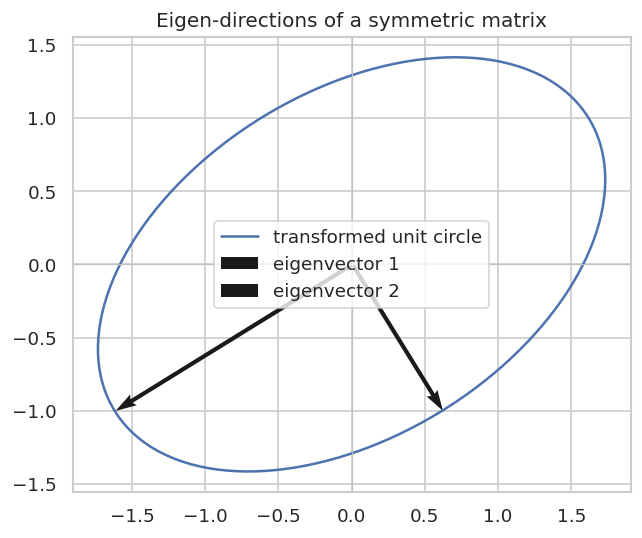

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_eig_A = np.array([[3.0, 1.0], [1.0, 2.0]])
viz_eig_vals, viz_eig_vecs = np.linalg.eigh(viz_eig_A)
viz_eig_theta = np.linspace(0, 2*np.pi, 300)
viz_eig_circle = np.vstack([np.cos(viz_eig_theta), np.sin(viz_eig_theta)])
viz_eig_ellipse = viz_eig_vecs @ np.diag(np.sqrt(viz_eig_vals)) @ viz_eig_circle
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(viz_eig_ellipse[0], viz_eig_ellipse[1], label="transformed unit circle")
for i in range(2):
    e = viz_eig_vecs[:, i] * np.sqrt(viz_eig_vals[i])
    ax.quiver(0, 0, e[0], e[1], angles="xy", scale_units="xy", scale=1, label=f"eigenvector {i+1}")
ax.axhline(0, color="0.75", lw=0.7); ax.axvline(0, color="0.75", lw=0.7)
ax.set_aspect("equal", adjustable="box"); ax.legend(); ax.set_title("Eigen-directions of a symmetric matrix"); plt.show()
display(pd.DataFrame({"eigenvalue": viz_eig_vals, "eigenvector x": viz_eig_vecs[0], "eigenvector y": viz_eig_vecs[1]}).round(3))

### A small PCA example

PCA centers the data, computes principal directions, and projects observations onto a lower-dimensional coordinate system. Here we keep the first principal component. Standardizing features can be important when measurement units differ; PCA itself does not automatically standardize variables.

variance explained by PC1: 0.926


04_eigenvalues_and_decompositions.ipynb:cell17:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
04_eigenvalues_and_decompositions.ipynb:cell17:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


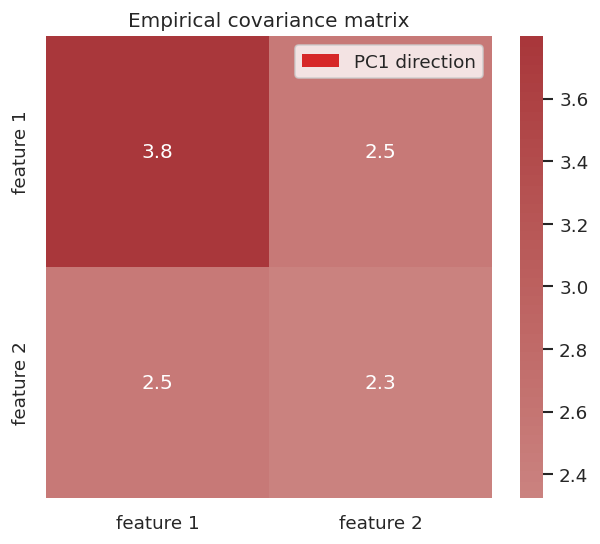

In [8]:
viz_pca_rng = np.random.default_rng(41)
viz_pca_cov = np.array([[4.0, 2.7], [2.7, 2.5]])
viz_pca_data = viz_pca_rng.multivariate_normal([2.0, -1.0], viz_pca_cov, size=250)
viz_pca_centered = viz_pca_data - viz_pca_data.mean(axis=0)
viz_pca_cov_emp = np.cov(viz_pca_centered, rowvar=False)
viz_pca_vals, viz_pca_vecs = np.linalg.eigh(viz_pca_cov_emp)
viz_pca_order = np.argsort(viz_pca_vals)[::-1]
viz_pca_vals, viz_pca_vecs = viz_pca_vals[viz_pca_order], viz_pca_vecs[:, viz_pca_order]
viz_pca_score = viz_pca_centered @ viz_pca_vecs[:, 0]
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(viz_pca_data[:, 0], viz_pca_data[:, 1], alpha=0.35, s=18)
viz_pca_origin = viz_pca_data.mean(axis=0)
ax.quiver(*viz_pca_origin, *(viz_pca_vecs[:, 0]*3), angles="xy", scale_units="xy", scale=1, color="tab:red", label="PC1 direction")
ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2"); ax.legend(); ax.set_title("Principal component captures dominant variation"); plt.show()
print("variance explained by PC1:", round(float(viz_pca_vals[0]/viz_pca_vals.sum()), 3))
sns.heatmap(viz_pca_cov_emp, annot=True, cmap="vlag", center=0, xticklabels=["feature 1", "feature 2"], yticklabels=["feature 1", "feature 2"])
plt.title("Empirical covariance matrix"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Reconstruct a matrix using all singular values.

In [9]:
A = np.array([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print(np.allclose(U @ np.diag(s) @ Vt, A))

True


### Exercise 2
Exercise 2: Check whether a symmetric matrix is positive definite.

In [10]:
A = np.array([[2.0, -1.0], [-1.0, 2.0]])
print(np.linalg.eigvalsh(A))
print(np.all(np.linalg.eigvalsh(A) > 0))

[1. 3.]
True


## Key takeaways
- Eigenvectors reveal invariant directions; eigenvalues describe their scaling.
- SVD is a robust general-purpose decomposition and underpins low-rank approximation and PCA.
- Choose a decomposition that matches matrix properties; not every matrix admits every factorization.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.